
CLASS-E / EPC2037 RESULTS
KR                 : 0.576801
KC                 : 0.183601
KL                 : 1.152494

Ropt               : 8.223 ohm
Csh ideal          : 253.830 pF
C external         : 247.330 pF
L1                 : 107.735 nH
L2                 : 280.439 nH
C2                 : 460.835 pF

NONLINEAR COSS MODEL
-------------------------------------------------------
Qoss(50V)          : 600.000 pC
Coss(50V)          : 6.500 pF
Coss(TR) datasheet : 12.000 pF
Model exponent     : 0.541667

OPERATING POINT
-------------------------------------------------------
IDC                : 348.016 mA
Drain voltage peak : 18.135 V
Turn-on voltage    : 0.93382 V
Load current peak  : 0.6935 A
Switch current peak: 2.3345 A
DC voltage residual: +0.000000 mV
Periodic state error: 9.997e-12

POWER BALANCE
-------------------------------------------------------
P_in                :  1687.8790 mW
P_source_actual     :  1687.8790 mW
P_load              :  1581.3024 mW
P_Ron              

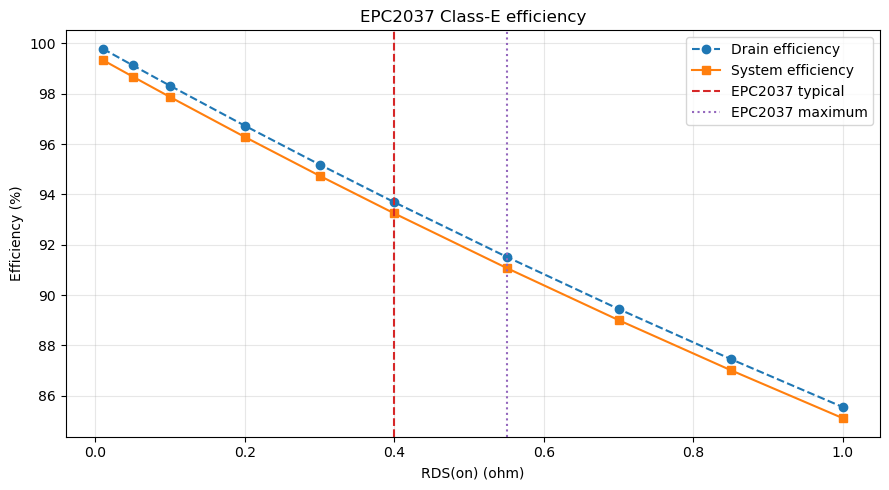

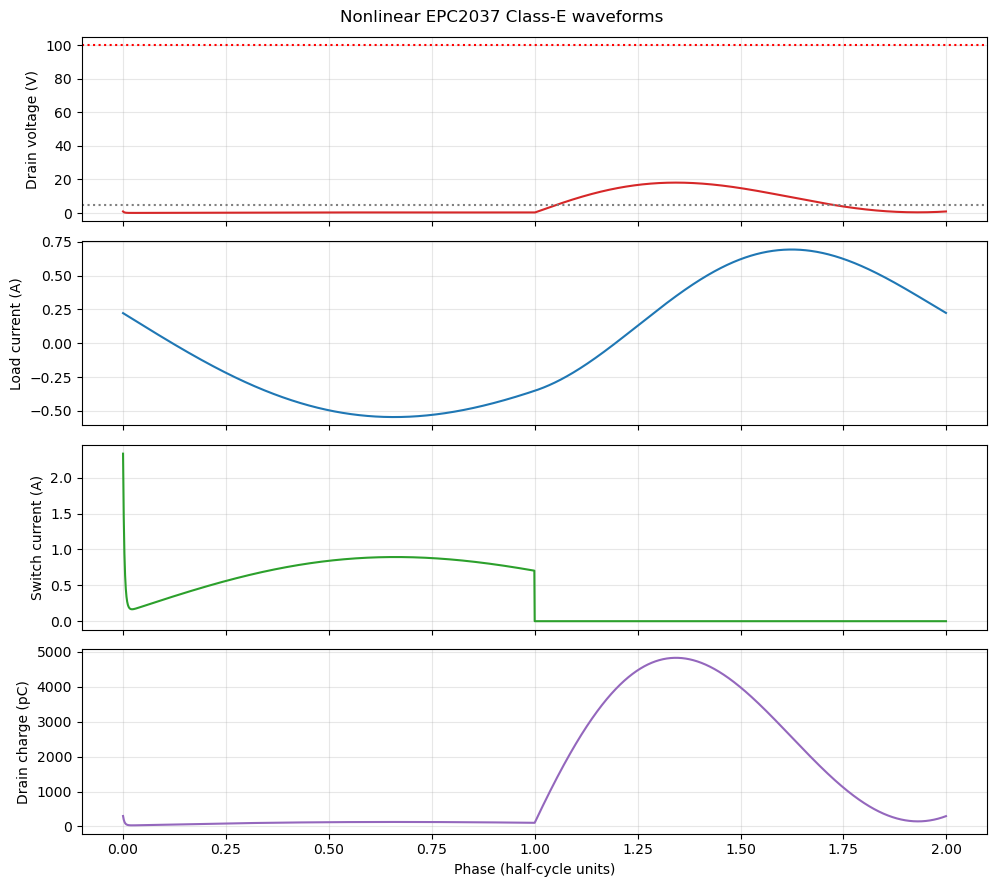

In [2]:

# ================================================================
# GaN CLASS-E AMPLIFIER — EPC2037
# Nonlinear Coss / charge-based switching / energy accounting
# ================================================================

import numpy as np
import matplotlib.pyplot as plt
from scipy.integrate import solve_ivp
from scipy.optimize import brentq

# 1. SPECIFICATIONS
VDD, P_OUT, F0 = 4.85, 1.65, 14e6
W0 = 2*np.pi*F0
T, TH = 1/F0, 1/(2*F0)
VDS_MAX, ID_MAX = 100.0, 1.7
RON_TYP, RON_MAX = 0.400, 0.550
VG, QG = 5.0, 115e-12
P_GATE = QG*VG*F0

# EPC2037 datasheet parameters
COSS_50 = 6.5e-12
COSS_TR = 12e-12
QOSS_50 = 600e-12

# 2. ANALYTICAL CLASS-E COEFFICIENTS
a = 2/np.sqrt(np.pi**2+4)
phi = np.pi-np.arctan(2/np.pi)
KR = 2*a**2
KC = 2*a**2/np.pi

Ropt = KR*VDD**2/P_OUT
Csh_ideal = KC/(W0*Ropt)

IR_norm = np.sqrt(2/KR)
IDC_norm = a*IR_norm
C_norm = KC/KR

th = np.linspace(0, 2*np.pi, 200001)
vd = np.zeros_like(th)
off = th >= np.pi
x = th[off]

vd[off] = (
    IDC_norm*(x-np.pi)
    + IR_norm*(np.cos(x+phi)-np.cos(np.pi+phi))
)/C_norm

V1 = np.trapezoid(vd*np.exp(-1j*th), th)/np.pi
I1 = IR_norm*np.exp(1j*(phi-np.pi/2))
Z1 = V1/I1
KL = Z1.imag/Z1.real

L1 = KL*Ropt/W0

# 3. NONLINEAR OUTPUT CHARGE MODEL
# Qoss(V) = Q50*(V/50)**M
# Coss(50V) = M*Q50/50

M = COSS_50*50/QOSS_50

def qoss(v):
    v = abs(float(v))
    return QOSS_50*(v/50)**M

def coss(v):
    v = max(abs(float(v)), 1e-12)
    return M*QOSS_50/50*(v/50)**(M-1)

def eoss(v):
    v = abs(float(v))
    return M/(M+1)*QOSS_50*50*(v/50)**(M+1)

# External capacitance: 50 V differential-capacitance
# reference approximation. COSS_TR is not interchangeable
# with COSS_50 and is retained as a datasheet reference.
C_external = Csh_ideal-COSS_50

if C_external <= 0:
    raise ValueError("External shunt capacitance is non-positive.")

def q_total(v):
    v = float(v)
    return C_external*v+np.sign(v)*qoss(v)

def e_total(v):
    v = float(v)
    return 0.5*C_external*v**2+eoss(v)

# Invert the nonlinear charge relation.
def voltage_from_charge(q):
    q = float(q)
    if abs(q) < 1e-30:
        return 0.0
    sign = np.sign(q)
    target = abs(q)
    upper = max(100.0, target/C_external+50.0)
    while q_total(upper) < target:
        upper *= 2
    return sign*brentq(
        lambda v: q_total(v)-target,
        0.0, upper, xtol=1e-12
    )

# 4. OUTPUT TANK
QL = 3.0
L2 = QL*Ropt/W0
C2 = 1/(W0**2*L2)
LT = L1+L2

# 5. SWITCHING DIFFERENTIAL EQUATIONS
# State: [Q_D, iL, v2]
#
# ON:  dQ/dt = IDC-iL-vD/RON
# OFF: dQ/dt = IDC-iL
#
# The switch current and capacitor current are
# therefore explicitly separated by KCL.

def make_on(IDC, RON):
    def f(t, y):
        q, iL, v2 = y
        vD = voltage_from_charge(q)
        iSW = vD/RON
        return [
            IDC-iL-iSW,
            (vD-v2-Ropt*iL)/LT,
            iL/C2
        ]
    return f

def make_off(IDC):
    def f(t, y):
        q, iL, v2 = y
        vD = voltage_from_charge(q)
        return [
            IDC-iL,
            (vD-v2-Ropt*iL)/LT,
            iL/C2
        ]
    return f

def cycle(IDC, RON=RON_TYP, warmup=300, samples=1200):
    if RON <= 0:
        raise ValueError("RON must be positive in the finite-resistance model.")

    fon, foff = make_on(IDC, RON), make_off(IDC)
    y = np.zeros(3)
    rtol, atol = 2e-8, 1e-12

    # Converge to periodic steady state.
    for k in range(warmup):
        s1 = solve_ivp(
            fon, (0, TH), y, method="LSODA",
            rtol=rtol, atol=atol
        )
        s2 = solve_ivp(
            foff, (0, TH), s1.y[:, -1],
            method="LSODA", rtol=rtol, atol=atol
        )
        yn = s2.y[:, -1]

        if np.max(np.abs(yn-y)) < 1e-10:
            y = yn
            break
        y = yn

    # Final complete cycle with dense output.
    s1 = solve_ivp(
        fon, (0, TH), y, method="LSODA",
        rtol=rtol, atol=atol, dense_output=True
    )
    s2 = solve_ivp(
        foff, (0, TH), s1.y[:, -1],
        method="LSODA", rtol=rtol,
        atol=atol, dense_output=True
    )

    t1 = np.linspace(0, TH, samples, endpoint=False)
    t2 = np.linspace(0, TH, samples, endpoint=False)
    y1, y2 = s1.sol(t1), s2.sol(t2)

    q = np.r_[y1[0], y2[0]]
    iL = np.r_[y1[1], y2[1]]
    v2 = np.r_[y1[2], y2[2]]
    t = np.r_[t1, TH+t2]

    vD = np.array([voltage_from_charge(z) for z in q])
    iSW = np.r_[vD[:samples]/RON, np.zeros(samples)]

    return {
        "t": t, "q": q, "v_D": vD,
        "i_L": iL, "i_sw": iSW, "v2": v2,
        "v_avg": np.trapezoid(vD, t)/T,
        "v_peak": np.max(vD),
        "v_turnon": voltage_from_charge(s2.y[0, -1]),
        "i_turnon": s2.y[1, -1],
        "periodic_error": np.max(np.abs(s2.y[:, -1]-y))
    }

# 6. SELF-CONSISTENT OPERATING POINT
def solve_operating_point(RON):
    cache = {}

    def residual(IDC):
        h = cycle(IDC, RON)
        cache[IDC] = h
        return h["v_avg"]-VDD

    lo, hi = 0.05*P_OUT/VDD, 3.0*P_OUT/VDD
    flo, fhi = residual(lo), residual(hi)

    if flo*fhi > 0:
        raise RuntimeError(
            f"No operating-point bracket for RON={RON:.3f} ohm: "
            f"residuals {flo:.4g}, {fhi:.4g}"
        )

    IDC = brentq(residual, lo, hi, xtol=1e-9)
    h = cycle(IDC, RON, warmup=500)
    return h, IDC, h["v_avg"]-VDD

# 7. POWER AND ENERGY ACCOUNTING
def power_report(h, IDC, RON):
    t, iL = h["t"], h["i_L"]
    iSW, vD = h["i_sw"], h["v_D"]

    P_IN = VDD*IDC
    P_LOAD = np.trapezoid(Ropt*iL**2, t)/T
    P_RON = np.trapezoid(RON*iSW**2, t)/T

    # Stored capacitor energy: diagnostic only.
    E_CAP = np.array([e_total(v) for v in vD])
    E_CAP_AVG = np.trapezoid(E_CAP, t)/T
    E_CAP_DELTA = E_CAP[-1]-E_CAP[0]

    # Instantaneous power balance:
    # source -> load + switch + capacitor + tank storage.
    P_SOURCE_ACTUAL = np.trapezoid(vD*IDC, t)/T

    # Switch dissipation is integrated directly.
    P_SWITCH = P_RON

    BALANCE = P_SOURCE_ACTUAL-P_LOAD-P_RON

    ETA_DRAIN = P_LOAD/P_IN
    ETA_SYSTEM = P_LOAD/(P_IN+P_GATE)

    return {
        "P_in": P_IN,
        "P_source_actual": P_SOURCE_ACTUAL,
        "P_load": P_LOAD,
        "P_Ron": P_RON,
        "P_Coss": 0.0,
        "P_ext": 0.0,
        "P_switch": P_SWITCH,
        "P_gate": P_GATE,
        "P_total": P_IN+P_GATE,
        "E_cap_avg": E_CAP_AVG,
        "E_cap_delta": E_CAP_DELTA,
        "balance": BALANCE,
        "eta_drain": ETA_DRAIN,
        "eta_system": ETA_SYSTEM
    }

# 8. MAIN OPERATING POINT
h, IDC, residual = solve_operating_point(RON_TYP)
p = power_report(h, IDC, RON_TYP)

print("\nCLASS-E / EPC2037 RESULTS")
print("="*55)
print(f"KR                 : {KR:.6f}")
print(f"KC                 : {KC:.6f}")
print(f"KL                 : {KL:.6f}")
print(f"\nRopt               : {Ropt:.3f} ohm")
print(f"Csh ideal          : {Csh_ideal*1e12:.3f} pF")
print(f"C external         : {C_external*1e12:.3f} pF")
print(f"L1                 : {L1*1e9:.3f} nH")
print(f"L2                 : {L2*1e9:.3f} nH")
print(f"C2                 : {C2*1e12:.3f} pF")

print("\nNONLINEAR COSS MODEL")
print("-"*55)
print(f"Qoss(50V)          : {qoss(50)*1e12:.3f} pC")
print(f"Coss(50V)          : {coss(50)*1e12:.3f} pF")
print(f"Coss(TR) datasheet : {COSS_TR*1e12:.3f} pF")
print(f"Model exponent     : {M:.6f}")

print("\nOPERATING POINT")
print("-"*55)
print(f"IDC                : {IDC*1e3:.3f} mA")
print(f"Drain voltage peak : {h['v_peak']:.3f} V")
print(f"Turn-on voltage    : {h['v_turnon']:.5f} V")
print(f"Load current peak  : {np.max(h['i_L']):.4f} A")
print(f"Switch current peak: {np.max(h['i_sw']):.4f} A")
print(f"DC voltage residual: {residual*1e3:+.6f} mV")
print(f"Periodic state error: {h['periodic_error']:.3e}")

print("\nPOWER BALANCE")
print("-"*55)
for key in [
    "P_in", "P_source_actual", "P_load",
    "P_Ron", "P_switch", "P_gate",
    "P_total", "balance"
]:
    print(f"{key:20s}: {p[key]*1e3:10.4f} mW")

print(f"\nDrain efficiency : {p['eta_drain']*100:.3f} %")
print(f"System efficiency: {p['eta_system']*100:.3f} %")
print(f"Average C energy : {p['E_cap_avg']*1e9:.4f} nJ")

# 9. DEVICE LIMITS
print("\nDEVICE LIMITS")
print("-"*55)
print(f"VDS peak : {h['v_peak']:.3f} / {VDS_MAX:.1f} V")
print(f"ID peak  : {np.max(h['i_L']):.3f} / {ID_MAX:.2f} A")
print(f"ISW peak : {np.max(h['i_sw']):.3f} A")

# 10. RON SWEEP
ron_values = np.array([
    0.01, 0.05, 0.10, 0.20, 0.30,
    0.40, 0.55, 0.70, 0.85, 1.00
])

sweep = []
print("\nRON SWEEP")
print("="*95)
print(
    f"{'RON':>6} {'IDC(mA)':>9} {'Vpk(V)':>9} "
    f"{'Pload(mW)':>11} {'PRon(mW)':>11} "
    f"{'Balance(mW)':>13} {'Drain(%)':>10} {'System(%)':>10}"
)

for ron in ron_values:
    hs, ids, res = solve_operating_point(ron)
    ps = power_report(hs, ids, ron)
    sweep.append([
        ron, ids, hs["v_peak"], ps["P_load"],
        ps["P_Ron"], ps["balance"],
        ps["eta_drain"], ps["eta_system"]
    ])
    print(
        f"{ron:6.2f} {ids*1e3:9.2f} "
        f"{hs['v_peak']:9.2f} "
        f"{ps['P_load']*1e3:11.3f} "
        f"{ps['P_Ron']*1e3:11.3f} "
        f"{ps['balance']*1e3:13.3f} "
        f"{ps['eta_drain']*100:10.2f} "
        f"{ps['eta_system']*100:10.2f}"
    )

sweep = np.asarray(sweep)

# 11. EFFICIENCY PLOT
fig, ax = plt.subplots(figsize=(9, 5))
ax.plot(sweep[:, 0], 100*sweep[:, 6], "o--", label="Drain efficiency")
ax.plot(sweep[:, 0], 100*sweep[:, 7], "s-", label="System efficiency")
ax.axvline(RON_TYP, color="C3", ls="--", label="EPC2037 typical")
ax.axvline(RON_MAX, color="C4", ls=":", label="EPC2037 maximum")
ax.set(
    xlabel="RDS(on) (ohm)",
    ylabel="Efficiency (%)",
    title="EPC2037 Class-E efficiency"
)
ax.grid(alpha=0.3)
ax.legend()
plt.tight_layout()

# 12. WAVEFORMS
phase = h["t"]/TH
fig, ax = plt.subplots(4, 1, figsize=(10, 9), sharex=True)

ax[0].plot(phase, h["v_D"], color="C3")
ax[0].axhline(VDD, color="gray", ls=":")
ax[0].axhline(VDS_MAX, color="red", ls=":")
ax[0].set_ylabel("Drain voltage (V)")
ax[0].grid(alpha=0.3)

ax[1].plot(phase, h["i_L"], color="C0")
ax[1].set_ylabel("Load current (A)")
ax[1].grid(alpha=0.3)

ax[2].plot(phase, h["i_sw"], color="C2")
ax[2].set_ylabel("Switch current (A)")
ax[2].grid(alpha=0.3)

ax[3].plot(phase, h["q"]*1e12, color="C4")
ax[3].set_ylabel("Drain charge (pC)")
ax[3].set_xlabel("Phase (half-cycle units)")
ax[3].grid(alpha=0.3)

fig.suptitle("Nonlinear EPC2037 Class-E waveforms")
plt.tight_layout()
plt.show()
